# GIAI ĐOẠN 5: HUẤN LUYỆN, TINH CHỈNH VÀ ĐÁNH GIÁ MÔ HÌNH HỌC MÁY

Trong giai đoạn này, nhóm em tiến hành triển khai các thí nghiệm thực chứng nhằm đánh giá khách quan sức mạnh dự báo của các thuật toán Học máy cổ điển (Classical Machine Learning) trên tập dữ liệu nhu cầu xe đạp công cộng UCI Bike Sharing:
- **Thí nghiệm 1 (Mục 1):** Đối chứng hiệu năng giữa Dữ liệu thô (Raw Data) và Dữ liệu đã qua Tiền xử lý & Chuẩn hóa (Cleaned & Scaled Data) trên 4 họ mô hình đại diện.
- **Kiểm chứng Capping (Mục 1b):** Huấn luyện trên `cnt` gốc và `cnt` đã Capping, đánh giá trên `cnt` gốc của tập Test.
- **Thí nghiệm 2 (Mục 2):** Huấn luyện, kiểm định chéo 5-Fold Cross Validation và tinh chỉnh siêu tham số GridSearchCV trên 9 cấu hình mô hình hồi quy (8 họ thuật toán).
- **Thí nghiệm 3 (Mục 3):** Mở rộng bài toán phân lớp nhu cầu Cao / Thấp và vẽ đường cong ROC-AUC.
- **Tổng kết & Đánh giá (Mục 4):** Xuất bảng so sánh tổng hợp các độ đo học thuật ($MAE, MSE, RMSE, MBE, R^2, Train Time$), phân tích Feature Importance và thử nghiệm hàm dự đoán trên mẫu thực tế.

# 1. Thí nghiệm 1: Đối chứng Hiệu năng giữa Dữ liệu thô và Dữ liệu làm sạch & chuẩn hóa

**Mục tiêu thí nghiệm:**
Chứng minh một cách định lượng giá trị thực tế của quy trình Tiền xử lý dữ liệu và Kỹ thuật đặc trưng (giai đoạn 4). Nhóm em đặt ra câu hỏi nghiên cứu: *Nếu đưa thẳng dữ liệu thô vào mô hình theo kiểu "hộp đen" thì kết quả sẽ sai lệch ra sao so với dữ liệu được xử lý bài bản theo quy trình Học máy cổ điển?*

**4 mô hình đại diện cho 4 trường phái thuật toán:**
1. **Linear Regression (Mô hình tham số tuyến tính):** Cực kỳ nhạy cảm với đa cộng tuyến và quan hệ phi tuyến.
2. **k-Nearest Neighbors (kNN - Mô hình phi tham số):** Phụ thuộc hoàn toàn vào khoảng cách Euclidean, rất nhạy cảm với thang đo và tính tuần hoàn thời gian.
3. **AdaBoost Regressor (Họ thuật toán Boosting):** Nhạy cảm với các điểm ngoại lai cực trị do cơ chế phạt tăng trọng số mẫu lỗi.
4. **Multi-layer Perceptron (MLPRegressor - Mạng ANN 3 lớp):** Đại diện cho Mạng nơ-ron nhân tạo với 3 tầng ẩn `(64, 32, 16)`, phụ thuộc mật thiết vào việc chuẩn hóa thang đo đầu vào.

**Thiết lập thực nghiệm:**
- **Dữ liệu thô (Raw Data):** Lấy trực tiếp từ `data/hour.csv` (chỉ loại bỏ các cột rò rỉ và định danh để đảm bảo tính hợp lệ cơ bản), giữ nguyên 22 dòng lỗi cảm biến, không lọc ngoại lai, không mã hóa chu kỳ $\sin/\cos$, không tạo `is_rush_hour`, không One-Hot và không chuẩn hóa thang đo.
- **Dữ liệu sạch (Cleaned & Scaled Data):** Sử dụng các tập `X_train_scaled.csv`, `X_test_scaled.csv` đã qua toàn bộ chuỗi tiền xử lý ở giai đoạn tiền xử lý dữ liệu.
- **Điều kiện so sánh công bằng:** cả hai phiên bản dùng **cùng một phép chia** 80/20 (`random_state=42`, cùng các dòng trong tập Test) và đều được đánh giá trên **`cnt` gốc chưa qua xử lý** của tập Test. Tập thô cố ý giữ `atemp` và 22 dòng `hum = 0` vì mục đích là mô phỏng cách làm "đưa thẳng dữ liệu vào mô hình".

C:\Users\ASUS\AppData\Local\Temp\claude\ff6cb903395d91ff\5051edbc-f68f-4899-9f30-6c41de00dcad\scratchpad\mlenv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


=== BẢNG ĐỐI CHỨNG HIỆU NĂNG: DỮ LIỆU THÔ VS. DỮ LIỆU SẠCH (THÍ NGHIỆM 1) ===


       Thuật toán  RMSE (Thô)  RMSE (Sạch)  % Giảm RMSE  R2 (Thô)  R2 (Sạch)   Tăng R2
Linear Regression  139.211452    89.963928    35.376058  0.387981   0.744405  0.356424
        kNN (k=5)   52.738091    57.000027    -8.081324  0.912166   0.897396 -0.014770
         AdaBoost  105.012180   100.364991     4.425382  0.651748   0.681889  0.030141
  ANN (MLP 3 lớp)   51.162747    40.717407    20.415910  0.917335   0.947643  0.030308


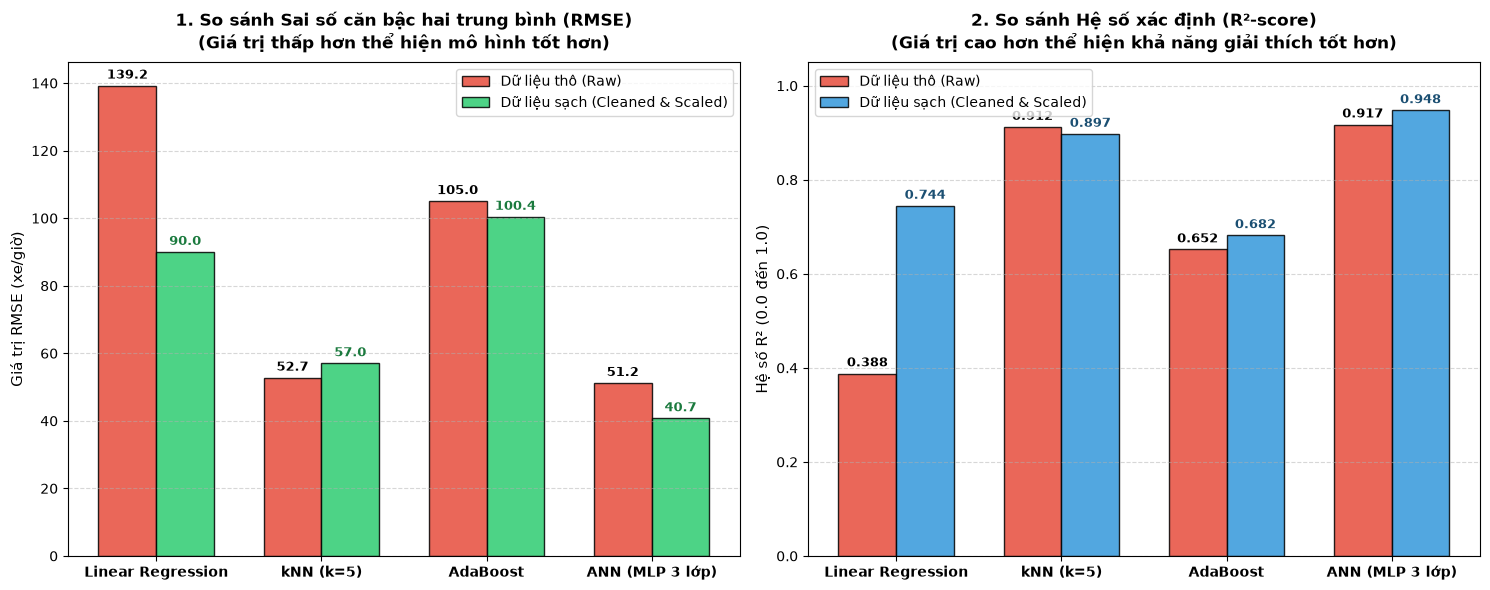

In [1]:
import pandas as pd
import numpy as np
import time
import os
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import AdaBoostRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Nạp tập dữ liệu thô (Raw Data)
data_path = "../data/hour.csv" if os.path.exists("../data/hour.csv") else "data/hour.csv"
df_raw = pd.read_csv(data_path)
raw_features = ["season", "yr", "mnth", "hr", "holiday", "weekday", "workingday", "weathersit", "temp", "atemp", "hum", "windspeed"]
X_raw = df_raw[raw_features]
y_raw = df_raw["cnt"]
X_raw_train, X_raw_test, y_raw_train, y_raw_test = train_test_split(X_raw, y_raw, test_size=0.2, random_state=42)

# 2. Nạp tập dữ liệu sạch & chuẩn hóa (Cleaned & Scaled Data từ giai đoạn tiền xử lý dữ liệu)
data_dir = "../data" if os.path.exists("../data") else "data"
X_clean_train = pd.read_csv(os.path.join(data_dir, "X_train_scaled.csv"))
X_clean_test = pd.read_csv(os.path.join(data_dir, "X_test_scaled.csv"))
y_clean_train = pd.read_csv(os.path.join(data_dir, "y_train.csv"))["cnt"]
y_clean_test = pd.read_csv(os.path.join(data_dir, "y_test.csv"))["cnt"]

# 3. Khởi tạo 4 mô hình đối chứng
models = {
    "Linear Regression": LinearRegression(),
    "kNN (k=5)": KNeighborsRegressor(n_neighbors=5),
    "AdaBoost": AdaBoostRegressor(random_state=42),
    "ANN (MLP 3 lớp)": MLPRegressor(hidden_layer_sizes=(64, 32, 16), max_iter=300, random_state=42)
}

# 4. Huấn luyện và thu thập chỉ số đánh giá
records = []
for name, model in models.items():
    # --- Đánh giá trên Dữ liệu thô ---
    t0 = time.time()
    model.fit(X_raw_train, y_raw_train)
    t_raw = time.time() - t0
    pred_raw = model.predict(X_raw_test)
    mae_raw = mean_absolute_error(y_raw_test, pred_raw)
    mse_raw = mean_squared_error(y_raw_test, pred_raw)
    rmse_raw = np.sqrt(mse_raw)
    mbe_raw = np.mean(pred_raw - y_raw_test)
    r2_raw = r2_score(y_raw_test, pred_raw)
    
    # --- Đánh giá trên Dữ liệu sạch & chuẩn hóa ---
    t0 = time.time()
    model.fit(X_clean_train, y_clean_train)
    t_clean = time.time() - t0
    pred_clean = model.predict(X_clean_test)
    mae_clean = mean_absolute_error(y_clean_test, pred_clean)
    mse_clean = mean_squared_error(y_clean_test, pred_clean)
    rmse_clean = np.sqrt(mse_clean)
    mbe_clean = np.mean(pred_clean - y_clean_test)
    r2_clean = r2_score(y_clean_test, pred_clean)
    
    # Tính % cải thiện RMSE (giảm càng nhiều càng tốt) và R2 (tăng càng nhiều càng tốt)
    rmse_imp = (rmse_raw - rmse_clean) / rmse_raw * 100
    r2_imp = (r2_clean - r2_raw)
    
    records.append({
        "Thuật toán": name,
        "RMSE (Thô)": rmse_raw,
        "RMSE (Sạch)": rmse_clean,
        "% Giảm RMSE": rmse_imp,
        "R2 (Thô)": r2_raw,
        "R2 (Sạch)": r2_clean,
        "Tăng R2": r2_imp,
        "MAE (Thô)": mae_raw,
        "MAE (Sạch)": mae_clean,
        "Thời gian (Thô)": t_raw,
        "Thời gian (Sạch)": t_clean
    })

df_results = pd.DataFrame(records)

# In bảng tổng hợp kết quả đối chứng
print("=== BẢNG ĐỐI CHỨNG HIỆU NĂNG: DỮ LIỆU THÔ VS. DỮ LIỆU SẠCH (THÍ NGHIỆM 1) ===")
summary_table = df_results[["Thuật toán", "RMSE (Thô)", "RMSE (Sạch)", "% Giảm RMSE", "R2 (Thô)", "R2 (Sạch)", "Tăng R2"]].copy()
print(summary_table.to_string(index=False))

# 5. Vẽ biểu đồ so sánh trực quan và lưu vào output/
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
x_pos = np.arange(len(df_results))
width = 0.35

# Panel 1: So sánh Sai số RMSE (Thấp hơn là tốt hơn)
rects1 = axes[0].bar(x_pos - width/2, df_results["RMSE (Thô)"], width, label="Dữ liệu thô (Raw)", color="#e74c3c", alpha=0.85, edgecolor="black")
rects2 = axes[0].bar(x_pos + width/2, df_results["RMSE (Sạch)"], width, label="Dữ liệu sạch (Cleaned & Scaled)", color="#2ecc71", alpha=0.85, edgecolor="black")
axes[0].set_title("1. So sánh Sai số căn bậc hai trung bình (RMSE)\n(Giá trị thấp hơn thể hiện mô hình tốt hơn)", fontsize=12, fontweight="bold", pad=10)
axes[0].set_ylabel("Giá trị RMSE (xe/giờ)", fontsize=11)
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(df_results["Thuật toán"], fontsize=10, fontweight="bold")
axes[0].legend(fontsize=10, frameon=True)
axes[0].grid(axis="y", linestyle="--", alpha=0.5)

# Thêm nhãn số trên đầu cột RMSE
for rect in rects1:
    h = rect.get_height()
    axes[0].annotate(f"{h:.1f}", xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold")
for rect in rects2:
    h = rect.get_height()
    axes[0].annotate(f"{h:.1f}", xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold", color="#1b7a3e")

# Panel 2: So sánh Hệ số xác định R2-score (Cao hơn là tốt hơn)
rects3 = axes[1].bar(x_pos - width/2, df_results["R2 (Thô)"], width, label="Dữ liệu thô (Raw)", color="#e74c3c", alpha=0.85, edgecolor="black")
rects4 = axes[1].bar(x_pos + width/2, df_results["R2 (Sạch)"], width, label="Dữ liệu sạch (Cleaned & Scaled)", color="#3498db", alpha=0.85, edgecolor="black")
axes[1].set_title("2. So sánh Hệ số xác định (R²-score)\n(Giá trị cao hơn thể hiện khả năng giải thích tốt hơn)", fontsize=12, fontweight="bold", pad=10)
axes[1].set_ylabel("Hệ số R² (0.0 đến 1.0)", fontsize=11)
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(df_results["Thuật toán"], fontsize=10, fontweight="bold")
axes[1].set_ylim(0, 1.05)
axes[1].legend(fontsize=10, frameon=True)
axes[1].grid(axis="y", linestyle="--", alpha=0.5)

# Thêm nhãn số trên đầu cột R2
for rect in rects3:
    h = rect.get_height()
    axes[1].annotate(f"{h:.3f}", xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold")
for rect in rects4:
    h = rect.get_height()
    axes[1].annotate(f"{h:.3f}", xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold", color="#1b4f72")

plt.tight_layout()
out_dir = "../output" if os.path.exists("../output") else "output"
plt.savefig(os.path.join(out_dir, "step3_models_01_raw_vs_clean.png"), dpi=300, bbox_inches="tight")
plt.show()

**Nhận xét từ Thí nghiệm 1 (cùng tập Test, cùng `cnt` gốc):**
1. **Hồi quy tuyến tính hưởng lợi rõ nhất:** $R^2$ tăng từ $0.388$ lên $0.744$, $RMSE$ giảm từ $139.2$ xuống $90.0$ xe/giờ (giảm $35.4\%$). Mô hình tuyến tính không tự học được quan hệ phi tuyến của giờ trong ngày, nên các đặc trưng $\sin/\cos$, `is_rush_hour`, `hour_cluster` và One-Hot mang lại cải thiện lớn.
2. **Mạng nơ-ron MLP** cải thiện từ $R^2 = 0.917$ lên $0.948$ ($RMSE$ $51.2 \to 40.7$, giảm $20.4\%$), chủ yếu nhờ chuẩn hóa thang đo đầu vào. *Lưu ý:* MLP dừng ở 300 vòng lặp khi chưa hội tụ hoàn toàn (có cảnh báo `ConvergenceWarning`).
3. **AdaBoost** chỉ cải thiện nhẹ ($R^2$ $0.652 \to 0.682$) và vẫn có sai lệch hệ thống lớn: $MBE \approx +60$ xe/giờ (dự đoán cao hơn thực tế), cho thấy cấu hình mặc định đang bị **underfitting** chứ không phải học vẹt ngoại lai.
4. **kNN giảm nhẹ** trên dữ liệu đã xử lý ($R^2$ $0.912 \to 0.897$). Nguyên nhân có thể là số chiều tăng từ 12 lên 24 và chuẩn hóa làm các biến nhị phân/One-Hot có trọng số ngang với các biến quan trọng như `hr`, khiến khoảng cách Euclidean kém đặc trưng hơn. Kết quả này cho thấy tiền xử lý **không cải thiện đồng đều** cho mọi thuật toán.

👉 **Kết luận:** tiền xử lý và kỹ thuật đặc trưng cải thiện rõ rệt các mô hình tuyến tính và mạng nơ-ron, nhưng tác dụng phụ thuộc vào từng thuật toán.


## 1b. Kiểm chứng giả thuyết: Capping ngoại lai có giúp mô hình tốt hơn không?

Ở giai đoạn tiền xử lý, nhóm em **không mặc định** cắt trần ngoại lai mà lưu riêng phiên bản `y_train_capped` (ngưỡng IQR theo mùa học từ tập Train). Thí nghiệm này huấn luyện cùng một mô hình trên hai phiên bản mục tiêu – `cnt` gốc và `cnt` đã Capping – và **luôn đánh giá trên `y_test` gốc** để trả lời khách quan: giới hạn trần các nhu cầu cực đại có giúp giảm sai số dự đoán nhu cầu thực tế hay không.


In [2]:
y_clean_train_capped = pd.read_csv(os.path.join(data_dir, "y_train_capped.csv"))["cnt"]

cap_models = {
    "Linear Regression": LinearRegression(),
    "AdaBoost": AdaBoostRegressor(random_state=42),
    "ANN (MLP 3 lớp)": MLPRegressor(hidden_layer_sizes=(64, 32, 16), max_iter=300, random_state=42),
}
cap_records = []
for name, model in cap_models.items():
    for label, y_tr in [("cnt gốc", y_clean_train), ("cnt Capping IQR", y_clean_train_capped)]:
        model.fit(X_clean_train, y_tr)
        pred = model.predict(X_clean_test)
        cap_records.append({
            "Thuật toán": name, "Mục tiêu huấn luyện": label,
            "RMSE": np.sqrt(mean_squared_error(y_clean_test, pred)),
            "MAE": mean_absolute_error(y_clean_test, pred),
            "MBE": np.mean(pred - y_clean_test),
            "R2": r2_score(y_clean_test, pred),
        })
df_cap = pd.DataFrame(cap_records)
print("=== KIỂM CHỨNG CAPPING (đánh giá trên y_test gốc) ===")
print(df_cap.round(3).to_string(index=False))


C:\Users\ASUS\AppData\Local\Temp\claude\ff6cb903395d91ff\5051edbc-f68f-4899-9f30-6c41de00dcad\scratchpad\mlenv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


=== KIỂM CHỨNG CAPPING (đánh giá trên y_test gốc) ===
       Thuật toán Mục tiêu huấn luyện    RMSE    MAE    MBE    R2
Linear Regression             cnt gốc  89.964 68.159  3.216 0.744
Linear Regression     cnt Capping IQR  90.069 67.833  0.393 0.744
         AdaBoost             cnt gốc 100.365 87.541 59.853 0.682
         AdaBoost     cnt Capping IQR  99.962 84.170 47.337 0.684
  ANN (MLP 3 lớp)             cnt gốc  40.717 25.013  3.301 0.948
  ANN (MLP 3 lớp)     cnt Capping IQR  43.907 26.484 -2.674 0.939


**Nhận xét từ thí nghiệm kiểm chứng Capping:**
- Với **Linear Regression** và **AdaBoost**, Capping gần như không thay đổi $R^2$ ($0.744 \to 0.744$; $0.682 \to 0.684$); chỉ làm giảm nhẹ $MAE$ và độ lệch $MBE$.
- Với **MLP**, Capping làm kết quả **kém đi** ($RMSE$ $40.7 \to 43.9$, $R^2$ $0.948 \to 0.939$), vì mô hình bị "dạy" rằng nhu cầu không vượt quá ngưỡng trần nên dự đoán thấp hơn thực tế ở các giờ cao điểm ($MBE$ chuyển sang âm).
- **Kết luận:** giả thuyết "ngoại lai làm mô hình học vẹt, cần cắt trần" **không được thực nghiệm ủng hộ** trên bộ dữ liệu này. Các nhu cầu cao là hành vi thực tế; nhóm em giữ `cnt` gốc làm mục tiêu huấn luyện chính cho các thí nghiệm tiếp theo.


# 2. Thí nghiệm 2: Huấn luyện, Tinh chỉnh tham số (GridSearchCV) và Đánh giá 5-Fold Cross Validation trên 9 cấu hình mô hình Hồi quy (8 họ thuật toán, Linear Regression gồm đơn biến và đa biến)

**Mục tiêu thí nghiệm:**
- Khảo sát toàn diện 8 họ thuật toán Hồi quy đại diện trong học máy cổ điển: Hồi quy tuyến tính (Đơn biến & Đa biến), Hồi quy điều chuẩn (Ridge L2, Lasso L1), Hồi quy phi tuyến dựa trên khoảng cách (kNN), Hồi quy dựa trên siêu phẳng tối ưu (SVR - RBF kernel), Cây quyết định (CART), Mô hình kết hợp Bagging (Random Forest) và Boosting (XGBoost).
- Áp dụng **5-Fold Cross Validation** kết hợp **GridSearchCV** (`n_jobs=-1`) với lưới siêu tham số gọn gàng (4–6 tổ hợp tiêu biểu) nhằm tìm ra điểm cân bằng tối ưu giữa độ phức tạp và sai số mô hình.
- Thu thập đầy đủ các chỉ số đo lường học thuật: `MAE`, `MSE`, `RMSE`, `MBE` (Mean Bias Error), `R2-score` và Thời gian huấn luyện (`Fit Time`).
- Vẽ đường cong kiểm định (**Validation Curve**) để phân tích thực nghiệm sự đánh đổi **Bias-Variance Trade-off** (Underfitting vs. Overfitting).

--- BẮT ĐẦU HUẤN LUYỆN 5-FOLD CROSS VALIDATION VÀ GRID SEARCH ---


[Simple Linear Regression] Thời gian: 26.50s | CV-RMSE: 166.60 | Test-RMSE: 160.77 | R2: 0.1837


[Multiple Linear Regression] Thời gian: 4.22s | CV-RMSE: 92.90 | Test-RMSE: 89.96 | R2: 0.7444


[Ridge Regression (L2)] Thời gian: 0.26s | CV-RMSE: 92.90 | Test-RMSE: 89.97 | R2: 0.7444


[Lasso Regression (L1)] Thời gian: 0.68s | CV-RMSE: 92.90 | Test-RMSE: 89.96 | R2: 0.7444


[kNN Regressor] Thời gian: 1.76s | CV-RMSE: 58.52 | Test-RMSE: 54.81 | R2: 0.9051


[Support Vector Regression (SVR)] Thời gian: 144.27s | CV-RMSE: 55.89 | Test-RMSE: 51.98 | R2: 0.9147


[CART Decision Tree] Thời gian: 1.13s | CV-RMSE: 55.32 | Test-RMSE: 49.67 | R2: 0.9221


[Random Forest (Bagging)] Thời gian: 69.61s | CV-RMSE: 43.59 | Test-RMSE: 39.99 | R2: 0.9495


[XGBoost (Boosting)] Thời gian: 12.71s | CV-RMSE: 40.29 | Test-RMSE: 38.27 | R2: 0.9538

=== BẢNG TỔNG HỢP KẾT QUẢ THÍ NGHIỆM 2 (5-FOLD CV & GRID SEARCH) ===
                        Mô hình                                Tham số tối ưu (Best Params)  CV-RMSE (5-Fold)    MAE      MSE   RMSE   MBE  R2-score  Thời gian (s)
       Simple Linear Regression                                                        None            166.60 123.20 25847.22 160.77  4.92    0.1837          26.50
     Multiple Linear Regression                                                        None             92.90  68.16  8093.51  89.96  3.22    0.7444           4.22
          Ridge Regression (L2)                                             {'alpha': 10.0}             92.90  68.15  8093.78  89.97  3.22    0.7444           0.26
          Lasso Regression (L1)                                             {'alpha': 0.01}             92.90  68.15  8093.12  89.96  3.22    0.7444           0.68
                  kNN 

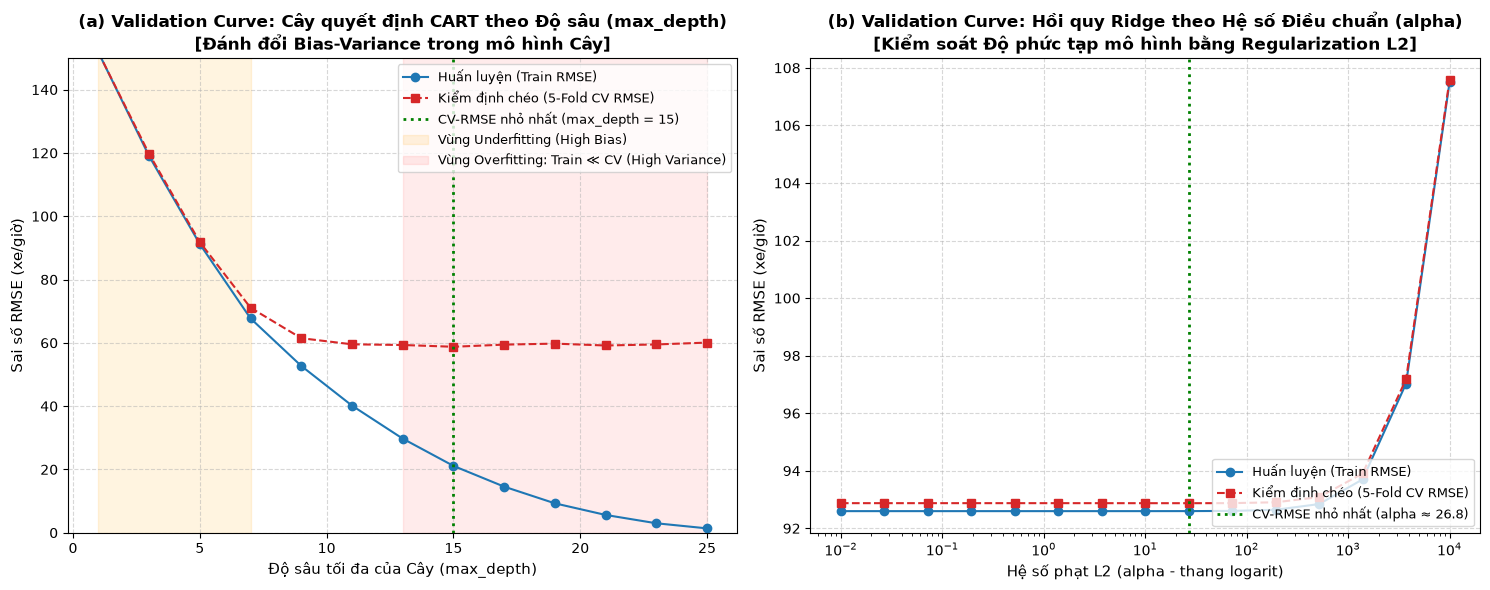

=== SỐ LIỆU VALIDATION CURVE ===
 max_depth  Train RMSE  CV RMSE
         1      151.80   151.78
         3      119.00   119.71
         5       91.19    91.82
         7       67.71    71.08
         9       52.70    61.46
        11       40.16    59.53
        13       29.73    59.31
        15       21.11    58.76
        17       14.56    59.43
        19        9.28    59.75
        21        5.62    59.16
        23        2.98    59.49
        25        1.37    60.07

Ridge: CV-RMSE nhỏ nhất = 92.87 tại alpha ≈ 26.8; tại alpha = 0.01: 92.87; tại alpha = 1e4: 107.59


In [3]:
# Huấn luyện và Đánh giá 5-Fold CV + GridSearchCV trên 9 cấu hình mô hình hồi quy
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import KFold, GridSearchCV, validation_curve
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import os

# 1. Đọc dữ liệu đã chuẩn hóa
X_train_df = pd.read_csv('../data/X_train_scaled.csv')
X_test_df = pd.read_csv('../data/X_test_scaled.csv')
y_train_arr = pd.read_csv('../data/y_train.csv').values.ravel()
y_test_arr = pd.read_csv('../data/y_test.csv').values.ravel()

cv_strategy = KFold(n_splits=5, shuffle=True, random_state=42)

# 2. Cấu hình 8 mô hình hồi quy đại diện và lưới siêu tham số gọn (4-6 tổ hợp)
models_config = {
    'Simple Linear Regression': {
        'model': LinearRegression(),
        'params': {},
        'single_feature': 'hr_sin'
    },
    'Multiple Linear Regression': {
        'model': LinearRegression(),
        'params': {}
    },
    'Ridge Regression (L2)': {
        'model': Ridge(random_state=42),
        'params': {'alpha': [0.1, 1.0, 10.0, 50.0]}
    },
    'Lasso Regression (L1)': {
        'model': Lasso(random_state=42, max_iter=2000),
        'params': {'alpha': [0.01, 0.1, 0.5, 1.0]}
    },
    'kNN Regressor': {
        'model': KNeighborsRegressor(n_jobs=-1),
        'params': {'n_neighbors': [3, 5, 7, 9], 'weights': ['distance']}
    },
    'Support Vector Regression (SVR)': {
        'model': SVR(),
        'params': {'C': [5, 15], 'gamma': ['scale', 0.05]}
    },
    'CART Decision Tree': {
        'model': DecisionTreeRegressor(random_state=42),
        'params': {'max_depth': [5, 10, 15, 20], 'min_samples_split': [5, 10]}
    },
    'Random Forest (Bagging)': {
        'model': RandomForestRegressor(random_state=42, n_jobs=-1),
        'params': {'n_estimators': [100, 150], 'max_depth': [15, 20]}
    },
    'XGBoost (Boosting)': {
        'model': XGBRegressor(random_state=42, n_jobs=-1, eval_metric='rmse'),
        'params': {'n_estimators': [100, 150], 'max_depth': [5, 7], 'learning_rate': [0.05, 0.1]}
    }
}

exp2_results = []
trained_best_models = {}

print('--- BẮT ĐẦU HUẤN LUYỆN 5-FOLD CROSS VALIDATION VÀ GRID SEARCH ---')
for model_name, cfg in models_config.items():
    t_start = time.time()
    if cfg.get('single_feature'):
        X_tr = X_train_df[[cfg['single_feature']]]
        X_te = X_test_df[[cfg['single_feature']]]
    else:
        X_tr = X_train_df
        X_te = X_test_df
        
    grid = GridSearchCV(
        cfg['model'],
        cfg['params'],
        cv=cv_strategy,
        scoring='neg_mean_squared_error',
        n_jobs=-1
    )
    grid.fit(X_tr, y_train_arr)
    fit_sec = time.time() - t_start
    
    best_m = grid.best_estimator_
    trained_best_models[model_name] = best_m
    y_pred = best_m.predict(X_te)
    
    mae = mean_absolute_error(y_test_arr, y_pred)
    mse = mean_squared_error(y_test_arr, y_pred)
    rmse = np.sqrt(mse)
    mbe = np.mean(y_pred - y_test_arr)
    r2 = r2_score(y_test_arr, y_pred)
    cv_rmse = np.sqrt(-grid.best_score_)
    params_str = str(grid.best_params_) if grid.best_params_ else 'None'
    
    print(f'[{model_name}] Thời gian: {fit_sec:.2f}s | CV-RMSE: {cv_rmse:.2f} | Test-RMSE: {rmse:.2f} | R2: {r2:.4f}')
    
    exp2_results.append({
        'Mô hình': model_name,
        'Tham số tối ưu (Best Params)': params_str,
        'CV-RMSE (5-Fold)': round(cv_rmse, 2),
        'MAE': round(mae, 2),
        'MSE': round(mse, 2),
        'RMSE': round(rmse, 2),
        'MBE': round(mbe, 2),
        'R2-score': round(r2, 4),
        'Thời gian (s)': round(fit_sec, 2)
    })

df_exp2 = pd.DataFrame(exp2_results)
print('\n=== BẢNG TỔNG HỢP KẾT QUẢ THÍ NGHIỆM 2 (5-FOLD CV & GRID SEARCH) ===')
print(df_exp2.to_string(index=False))

# 3. Vẽ biểu đồ Validation Curve minh họa Bias-Variance Trade-off
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Panel A: Decision Tree depth (minh họa Underfitting -> Sweet Spot -> Overfitting)
param_range_tree = np.arange(1, 26, 2)
train_scores_tree, test_scores_tree = validation_curve(
    DecisionTreeRegressor(random_state=42),
    X_train_df, y_train_arr,
    param_name='max_depth',
    param_range=param_range_tree,
    cv=cv_strategy,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)
train_rmse_tree = -np.mean(train_scores_tree, axis=1)
test_rmse_tree = -np.mean(test_scores_tree, axis=1)

axes[0].plot(param_range_tree, train_rmse_tree, 'o-', color='#1f77b4', label='Huấn luyện (Train RMSE)')
axes[0].plot(param_range_tree, test_rmse_tree, 's--', color='#d62728', label='Kiểm định chéo (5-Fold CV RMSE)')
best_depth = int(param_range_tree[np.argmin(test_rmse_tree)])
axes[0].axvline(x=best_depth, color='green', linestyle=':', linewidth=2, label=f'CV-RMSE nhỏ nhất (max_depth = {best_depth})')
axes[0].fill_between(param_range_tree[param_range_tree <= 7], 0, 160, color='orange', alpha=0.12, label='Vùng Underfitting (High Bias)')
axes[0].fill_between(param_range_tree[param_range_tree >= 13], 0, 160, color='red', alpha=0.08, label='Vùng Overfitting: Train ≪ CV (High Variance)')
axes[0].set_ylim(0, 150)
axes[0].set_title('(a) Validation Curve: Cây quyết định CART theo Độ sâu (max_depth)\n[Đánh đổi Bias-Variance trong mô hình Cây]', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Độ sâu tối đa của Cây (max_depth)', fontsize=11)
axes[0].set_ylabel('Sai số RMSE (xe/giờ)', fontsize=11)
axes[0].legend(loc='upper right', fontsize=9)
axes[0].grid(True, linestyle='--', alpha=0.5)

# Panel B: Ridge Regression alpha (minh họa Điều chuẩn L2 kiểm soát Variance)
param_range_ridge = np.logspace(-2, 4, 15)
train_scores_ridge, test_scores_ridge = validation_curve(
    Ridge(random_state=42),
    X_train_df, y_train_arr,
    param_name='alpha',
    param_range=param_range_ridge,
    cv=cv_strategy,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)
train_rmse_ridge = -np.mean(train_scores_ridge, axis=1)
test_rmse_ridge = -np.mean(test_scores_ridge, axis=1)

axes[1].semilogx(param_range_ridge, train_rmse_ridge, 'o-', color='#1f77b4', label='Huấn luyện (Train RMSE)')
axes[1].semilogx(param_range_ridge, test_rmse_ridge, 's--', color='#d62728', label='Kiểm định chéo (5-Fold CV RMSE)')
best_alpha = param_range_ridge[np.argmin(test_rmse_ridge)]
axes[1].axvline(x=best_alpha, color='green', linestyle=':', linewidth=2, label=f'CV-RMSE nhỏ nhất (alpha ≈ {best_alpha:.3g})')
axes[1].set_title('(b) Validation Curve: Hồi quy Ridge theo Hệ số Điều chuẩn (alpha)\n[Kiểm soát Độ phức tạp mô hình bằng Regularization L2]', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Hệ số phạt L2 (alpha - thang logarit)', fontsize=11)
axes[1].set_ylabel('Sai số RMSE (xe/giờ)', fontsize=11)
axes[1].legend(loc='lower right', fontsize=9)
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('../output/step3_models_02_bias_variance.png', dpi=300, bbox_inches='tight')
plt.show()

print('=== SỐ LIỆU VALIDATION CURVE ===')
print(pd.DataFrame({'max_depth': param_range_tree, 'Train RMSE': train_rmse_tree.round(2), 'CV RMSE': test_rmse_tree.round(2)}).to_string(index=False))
print()
print(f'Ridge: CV-RMSE nhỏ nhất = {test_rmse_ridge.min():.2f} tại alpha ≈ {best_alpha:.3g}; tại alpha = 0.01: {test_rmse_ridge[0]:.2f}; tại alpha = 1e4: {test_rmse_ridge[-1]:.2f}')

out_dir = '../output'
df_exp2.to_csv(os.path.join(out_dir, 'step3_models_exp2_results.csv'), index=False, encoding='utf-8-sig')

**Nhận xét từ Thí nghiệm 2:**

1. **Đánh đổi Bias-Variance (Hình `step3_models_02_bias_variance.png`):**
   - **Cây quyết định CART (Hình a):** khi cây nông ($max\_depth \le 7$), sai số Train và CV đều cao và gần bằng nhau ($RMSE \approx 71 - 152$) – dấu hiệu **Underfitting (High Bias)**. Sai số CV giảm nhanh và chạm đáy khoảng $58.8$ xe/giờ quanh $max\_depth = 15$, sau đó gần như đi ngang ($\approx 59 - 60$). Trong khi đó sai số Train tiếp tục giảm về gần $0$ ($1.4$ tại $max\_depth = 25$): khoảng cách Train–CV ngày càng lớn là biểu hiện của **Overfitting (High Variance)** – cây sâu hơn chỉ ghi nhớ thêm dữ liệu Train mà không cải thiện khả năng tổng quát hóa.
   - **Ridge L2 (Hình b):** sai số CV gần như không đổi ($\approx 92.9$) khi $\alpha$ từ $0.01$ đến khoảng $100$, và chỉ tăng khi $\alpha$ rất lớn ($107.6$ tại $\alpha = 10^4$, do phạt quá mạnh gây underfitting). Nguyên nhân: số mẫu ($\approx 13.900$) lớn hơn rất nhiều so với số đặc trưng (24), nên mô hình tuyến tính vốn ít bị overfitting; điều chuẩn L2/L1 **không mang lại cải thiện đáng kể** ở bài toán này. Giới hạn của nhóm tuyến tính nằm ở **bias** (không biểu diễn được quan hệ phi tuyến), không phải variance.

2. **So sánh các họ thuật toán (đánh giá trên tập Test, `cnt` gốc):**
   - **Hồi quy đơn biến** (chỉ dùng `hr_sin`): $R^2 = 0.184$, cho thấy một đặc trưng đơn lẻ không đủ giải thích nhu cầu.
   - **Nhóm tuyến tính (OLS, Ridge, Lasso):** $R^2 \approx 0.744$, $RMSE \approx 90.0$ xe/giờ, ba mô hình gần như trùng kết quả.
   - **Nhóm phi tuyến dựa trên khoảng cách/hạt nhân:** kNN ($R^2 = 0.905$, $RMSE = 54.8$) và SVR ($R^2 = 0.915$, $RMSE = 52.0$); SVR tốn thời gian huấn luyện lớn nhất (khoảng $144$ giây cho lưới tham số) do độ phức tạp tăng nhanh theo số mẫu.
   - **Cây quyết định CART:** $R^2 = 0.922$, $RMSE = 49.7$.
   - **Nhóm Ensemble:** Random Forest ($R^2 = 0.950$, $RMSE = 40.0$, khoảng $58$ giây) và **XGBoost cho kết quả tốt nhất** với $R^2 = 0.954$, $RMSE = 38.3$ xe/giờ, $MAE = 23.3$ – giảm $57.5\%$ $RMSE$ so với hồi quy tuyến tính đa biến, thời gian huấn luyện khoảng $13$ giây.
   - Sai số CV và sai số Test của các mô hình khá gần nhau, cho thấy kết quả ổn định. Tuy nhiên do chia ngẫu nhiên trên dữ liệu chuỗi thời gian, các con số này có thể **lạc quan hơn** so với tình huống dự báo tương lai thực sự.

*Thời gian huấn luyện phụ thuộc cấu hình máy; số liệu chỉ có ý nghĩa so sánh tương đối. Bảng kết quả đầy đủ được lưu tại `output/step3_models_exp2_results.csv`.*
